# NLP Assignment 1 — Fine-grained emotion detection with GoEmotions
**Phase 1: data, exploration, tokenization and text cleaning (Tasks 2–5)**

Team: *add names / IDs here* · Course: *add course / section* · Date: *add date*

**How this notebook is organised.** Every section follows the same pattern: *measure → decide → verify*. Cleaning decisions are
never made from habit ("always remove stop words"); each one is justified by a number computed on this dataset.

| Section | Content |
|---|---|
| Task 1 recap | dataset card |
| Task 2 | corpus statistics, target distribution, vocabulary / Zipf, data quality, messy-text inventory |
| Task 3 | five tokenizers compared on real comments, the regex patterns we use, tokenization challenges |
| Task 4 | the cleaning pipeline: design, step-by-step trace, case folding, stop words, stemming vs lemmatization, before/after |
| Task 5 | one command that reproduces the cleaned dataset, verified against this notebook |

The reusable code lives in `src/` (`load_data.py`, `cleaning.py`, `run_cleaning.py`); this notebook only *calls* it, so what you see here is exactly what the script runs.

In [1]:
import re, sys, time, json, subprocess, unicodedata
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from IPython.display import display

def find_project_root():
    """Locate the folder that contains src/cleaning.py, wherever Jupyter was started:
    the repo root, notebooks/, a parent folder of the repo, or a sub-folder of it."""
    start = Path.cwd().resolve()
    for base in (start, *start.parents):
        for candidate in (base, base / "goemotions-nlp"):
            if (candidate / "src" / "cleaning.py").exists():
                return candidate
    raise FileNotFoundError(
        f"Could not find the project's src/ folder from {start}.\n"
        "This notebook needs the whole project, not just the .ipynb file: unzip goemotions-nlp.zip "
        "and open notebooks/01_phase1_exploration_and_cleaning.ipynb from inside it "
        "(on Colab/Kaggle, upload the zip, unzip it, and %cd goemotions-nlp/notebooks first)."
    )

ROOT = find_project_root()
sys.path.insert(0, str(ROOT))

from src import cleaning as C
from src.load_data import load_goemotions, emotion_names, multi_hot

for resource in ("punkt_tab", "stopwords", "wordnet"):
    nltk.download(resource, quiet=True)

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 170)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEED = 42

df = load_goemotions()            
NAMES = emotion_names()
print(f"{len(df):,} comments | {len(NAMES)} labels | splits: {df.split.value_counts().to_dict()}")


SHUFFLED = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

def pick(pattern, n=1, max_len=130, flags=0):
    """First n real comments (in the fixed shuffle) matching a regex."""
    rx = re.compile(pattern, flags)
    hits = SHUFFLED[SHUFFLED.text.map(lambda t: bool(rx.search(t)) and len(t) <= max_len)]
    return hits.text.head(n).tolist()

# a real ALL-CAPS word: 3+ capitals, not part of a [NAME]-style placeholder
CAPS = r"(?<![\[A-Za-z])[A-Z]{3,}(?![A-Za-z\]])"

df.head()

54,263 comments | 28 labels | splits: {'train': 43410, 'test': 5427, 'validation': 5426}


,comment_id,split,text,label_ids,label_names
0,eebbqej,train,My favourite food is anything I didn't have to cook myself.,27,neutral
1,ed00q6i,train,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actuall...",27,neutral
2,eezlygj,train,WHY THE FUCK IS BAYLESS ISOING,2,anger
3,ed7ypvh,train,To make her feel threatened,14,fear
4,ed0bdzj,train,Dirty Southern Wankers,3,annoyance


## Task 1 recap — dataset card

| | |
|---|---|
| **Dataset** | GoEmotions (Demszky et al., 2020), Google Research |
| **Source** | https://github.com/google-research/google-research/tree/master/goemotions |
| **Content** | English Reddit comments, each annotated by crowd-workers |
| **Version used** | the *filtered* ("simplified") release: **54,263** comments kept out of the 58,009 raw ones, after dropping examples the raters could not agree on |
| **Splits** | the authors' predefined split: 43,410 train / 5,426 validation / 5,427 test (≈ 80 / 10 / 10) |
| **Prediction target** | 27 emotion labels + `neutral`, **multi-label** (a comment can carry several) |
| **Licence** | Apache 2.0 (as stated in the Google Research repository) |
| **Loading** | `python -m src.load_data` downloads the files into `data/raw/` (git-ignored; raw data is never committed) |

**Why the filtered release and not the raw one?** The raw files contain one row per *rater*, so using them would force us to invent a label-aggregation rule and to include comments the annotators themselves could not label. The filtered release has that step already done by the dataset authors and ships fixed splits, which makes our later results comparable with published GoEmotions numbers. The price is that we cannot say "58,009 examples" about the data we actually use, so the report states both numbers.

**Parsing pitfall (found and fixed).** The GoEmotions TSV files use CSV-style quoting: a comment that contains a double quote is wrapped in quotes and its inner quotes are doubled (`"Three words. ""Dude. Stop."" "` instead of `Three words. "Dude. Stop."`). Reading the files with `quoting=3` (no quote handling) leaves that escaping in the text of **1,383 comments (2.5%)**, which inflated the vocabulary counts and left `""` noise in the BERT input column. `src/load_data.py` now uses pandas' default quoting, and `load_goemotions` raises an error if more than 0.5% of comments contain a doubled quote, so the mistake cannot return silently. All numbers in this notebook were recomputed after the fix.

---
# Task 2 — Explore the corpus

## 2.1 Size, length and target distribution

,words,characters
count,54263.00,54263.00
mean,12.82,68.33
std,6.70,36.70
min,1.00,2.00
25%,7.00,38.00
50%,12.00,65.00
75%,18.00,96.00
max,33.00,703.00


,comments,share_pct
split,,
train,43410,80.0
test,5427,10.0
validation,5426,10.0


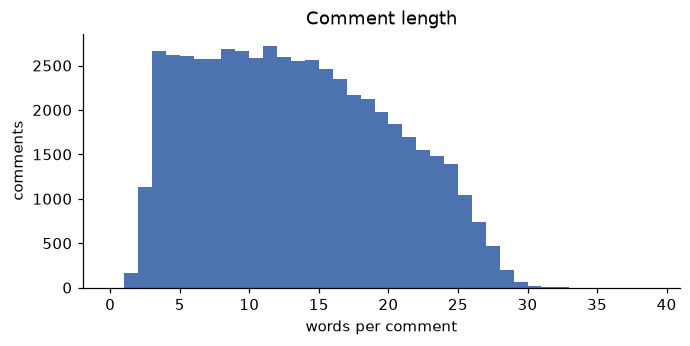

In [19]:
words = df.text.str.split().str.len()
chars = df.text.str.len()
display(pd.DataFrame({"words": words.describe(), "characters": chars.describe()}).round(2))
display(df.split.value_counts().to_frame("comments")
          .assign(share_pct=lambda x: (100 * x.comments / len(df)).round(1)))

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(words, bins=range(0, 40), color="#4C72B0")
ax.set_xlabel("words per comment"); ax.set_ylabel("comments"); ax.set_title("Comment length")
plt.show()

**What this tells us.** The comments are *very short*: median 12 words, three quarters have 18 words or fewer, the longest has 33 words. (The 703-*character* maximum is a 14-word comment containing one 633-digit string, `9999…`: character length is dominated by a few outliers like this, which is one reason Task 4 masks numbers.) Two consequences drive later choices:

1. With ~13 words per comment, every single token matters. A stop-word list that deletes "not" or "why" removes a large share of the evidence in a sentence. This is why Task 4 uses a custom stop-word list.
2. Almost no document is long enough to need truncation for BERT (its limit is 512 sub-word tokens), so Phase 2 can use a small `max_length` and train quickly.

The split is exactly 80 / 10 / 10.

,comments,share_pct
neutral,17772,32.75
admiration,5122,9.44
approval,3687,6.79
gratitude,3372,6.21
annoyance,3093,5.70
amusement,2895,5.34
curiosity,2723,5.02
disapproval,2581,4.76
love,2576,4.75
optimism,1976,3.64


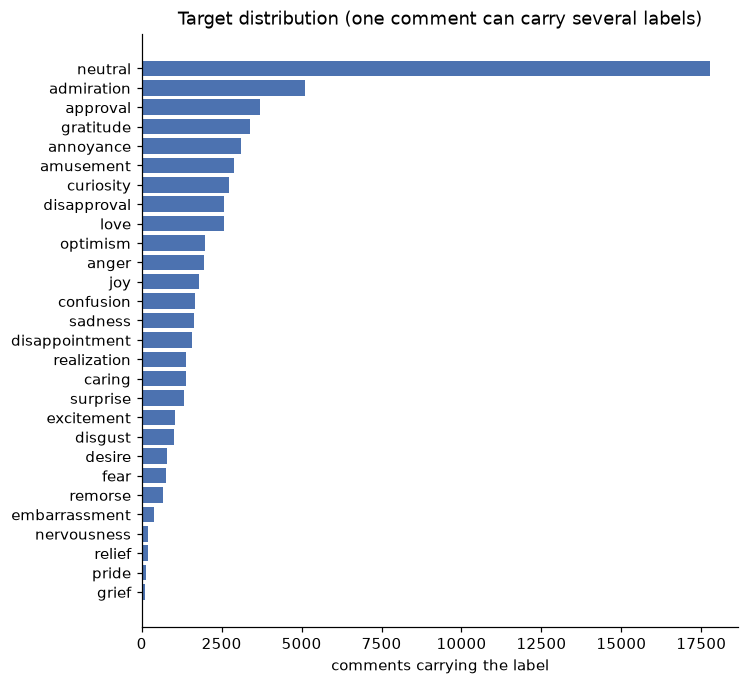

,comments,share_pct
labels per comment,,
1,45446,83.75
2,8124,14.97
3,655,1.21
4,37,0.07
5,1,0.00


label cardinality (mean labels per comment): 1.176
imbalance among the 27 emotions: admiration (5,122) vs grief (96) = 53x
largest train-vs-test gap in any label's frequency: 0.50 percentage points


In [20]:
Y = multi_hot(df, NAMES)                      # 0/1 matrix: one column per label
counts = Y.sum().sort_values(ascending=False)
dist = pd.DataFrame({"comments": counts, "share_pct": (100 * counts / len(df)).round(2)})
display(dist)

fig, ax = plt.subplots(figsize=(7, 7))
ax.barh(dist.index[::-1], dist.comments[::-1], color="#4C72B0")
ax.set_xlabel("comments carrying the label")
ax.set_title("Target distribution (one comment can carry several labels)")
plt.show()

per_comment = Y.sum(axis=1)
display(per_comment.value_counts().sort_index().to_frame("comments")
          .rename_axis("labels per comment")
          .assign(share_pct=lambda x: (100 * x.comments / len(df)).round(2)))
print(f"label cardinality (mean labels per comment): {per_comment.mean():.3f}")
emo = counts.drop("neutral")
print(f"imbalance among the 27 emotions: {emo.index[0]} ({emo.iloc[0]:,}) vs {emo.index[-1]} ({emo.iloc[-1]:,}) "
      f"= {emo.iloc[0] / emo.iloc[-1]:.0f}x")
gap = (Y[df.split == "train"].mean() - Y[df.split == "test"].mean()).abs().max()
print(f"largest train-vs-test gap in any label's frequency: {100 * gap:.2f} percentage points")

**What this tells us.**

* **Heavy imbalance.** `neutral` is the largest class (17,772 comments, 32.75%). Among the 27 emotions, `admiration` has 5,122 examples while `grief` has 96 — a **53×** gap — and `pride`, `relief` and `nervousness` have only 142, 182 and 208. A classifier that predicts the big classes and ignores the rare ones will still post a decent *accuracy*, so Phase 2 must report **per-class and macro-averaged F1**, and consider class weights.
* **Multi-label, but mostly single-label.** 83.75% of comments have exactly one label, 14.97% have two and only 1.28% have three or more (mean 1.18 labels per comment). Multi-label modelling is still necessary — one comment in six would otherwise be forced into a single class — but a model that only ever predicts one label already gets the majority right.
* **The splits are representative.** No label's frequency differs between train and test by more than 0.5 percentage points, so the provided splits do not need re-stratifying and we keep them untouched.

## 2.2 Vocabulary, type–token ratio and Zipf's law

,comments,tokens,types,type_token_ratio
0,500,6268,2284,0.364
1,1000,12599,3886,0.308
2,2000,25704,6465,0.252
3,5000,64359,12138,0.189
4,10000,127909,19144,0.150
5,20000,256051,30075,0.117
6,54263,695858,56964,0.082


full corpus: 695,858 tokens, 56,964 types
types occurring exactly once: 35,477 = 62.3% of types but 5.10% of tokens
top-100 types cover 47.7% of tokens, top-1000 cover 73.7%


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
token,the,i,to,a,and,you,is,that,of,it,this,[name],in,for,was,my,but,not,be,just
count,22294,19875,15509,15387,11173,10765,10142,8952,8844,7781,7261,7199,7103,7060,4813,4709,4438,4382,4293,4250


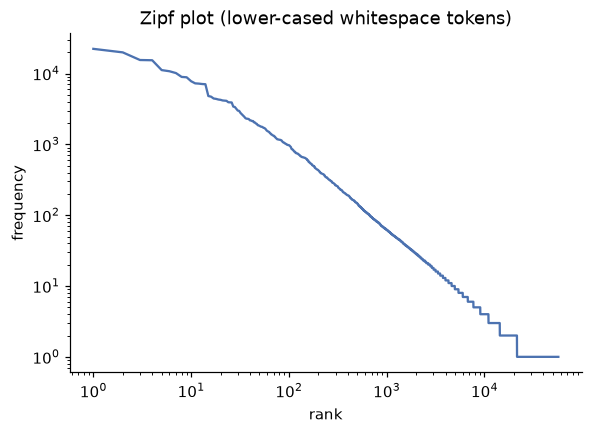

In [22]:
def simple_tokens(text):                       # deliberately naive: lower-case + whitespace split
    return text.lower().split()

checkpoints = {500, 1_000, 2_000, 5_000, 10_000, 20_000, len(SHUFFLED)}
seen, n_tokens, rows = set(), 0, []
for i, text in enumerate(SHUFFLED.text, 1):
    toks = simple_tokens(text)
    n_tokens += len(toks); seen.update(toks)
    if i in checkpoints:
        rows.append({"comments": i, "tokens": n_tokens, "types": len(seen),
                     "type_token_ratio": round(len(seen) / n_tokens, 3)})
display(pd.DataFrame(rows))

freq = Counter(w for t in df.text for w in simple_tokens(t))
total = sum(freq.values())
ranked = np.array(sorted(freq.values(), reverse=True))
hapax = int((ranked == 1).sum())
print(f"full corpus: {total:,} tokens, {len(freq):,} types")
print(f"types occurring exactly once: {hapax:,} = {100 * hapax / len(freq):.1f}% of types but {100 * hapax / total:.2f}% of tokens")
print(f"top-100 types cover {100 * ranked[:100].sum() / total:.1f}% of tokens, top-1000 cover {100 * ranked[:1000].sum() / total:.1f}%")
display(pd.DataFrame(freq.most_common(20), columns=["token", "count"]).T)

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(np.arange(1, len(ranked) + 1), ranked, color="#4C72B0")
ax.set_xlabel("rank"); ax.set_ylabel("frequency"); ax.set_title("Zipf plot (lower-cased whitespace tokens)")
plt.show()

**What this tells us.**

* **Types vs tokens.** The corpus has 695,858 tokens but only 56,964 distinct types (naive lower-cased whitespace tokens). The **type–token ratio falls from 0.364 at 500 comments to 0.082 on the full corpus** — so a TTR is only comparable between samples of the *same size*; the vocabulary keeps growing, but more and more slowly, because the same common words repeat while new rare ones trickle in.
* **Zipf's law.** The log–log rank/frequency plot is close to a straight line: a handful of words are extremely frequent (the top 100 types cover 47.7% of all tokens; the top 1,000 cover 73.7%) and a very long tail is extremely rare. 35,477 types — **62.3% of the vocabulary — occur exactly once** (hapax legomena), yet they make up only 5.1% of the tokens.
* **What the tail is made of.** Misspellings, slang, names, elongated words ("yaaaas"), emoji runs, case variants of the same word. A bag-of-words model sees each as an unrelated feature seen once — useless for learning. Much of the cleaning in Task 4 is therefore aimed at **collapsing variants of the same word into one type**.
* `[NAME]` is the 12th most frequent token (7,199 occurrences): it is a placeholder inserted by the dataset authors, not a real word, which is why Task 3 treats it explicitly.

In [23]:
dups = df[df.text.duplicated(keep=False)]
by_text = dups.groupby("text").agg(copies=("comment_id", "size"),
                                   splits=("split", lambda s: len(set(s))),
                                   distinct_label_sets=("label_ids", lambda s: len(set(s))))
print(f"{df.text.duplicated().sum()} surplus duplicate rows across {len(by_text)} distinct texts")
print(f"texts present in more than one split (leakage risk): {(by_text.splits > 1).sum()}")
print(f"duplicated texts whose copies carry different labels: {(by_text.distinct_label_sets > 1).sum()}")
display(by_text.sort_values("copies", ascending=False).head(8))

269 surplus duplicate rows across 166 distinct texts
texts present in more than one split (leakage risk): 71
duplicated texts whose copies carry different labels: 74


,copies,splits,distinct_label_sets
text,,,
Thank you.,15,3,1
Thank you!,11,3,1
Happy cake day!,9,3,4
Weird flex but ok,7,3,4
I like it,6,2,1
Good luck!,6,2,3
[NAME],6,1,2
I love [NAME],6,1,1


**Data-quality findings (to be handled consciously in Phase 2).**

* 269 surplus rows are exact duplicates, spread over 166 distinct texts — mostly short, generic comments ("Thank you.", "Happy cake day!").
* **71 of these texts occur in more than one split**, i.e. the same sentence can sit in both train and test (a small but real leakage risk).
* **74 duplicated texts carry different labels** across their copies ("Happy cake day!" appears 9 times with 4 different label sets). That is genuine annotation ambiguity and a reminder that the ceiling for any model on this task is not 100%.

**Decision:** we do **not** drop them in Phase 1. The assignment requires the dataset to stay the same across phases and removing rows would silently alter the authors' official test set; the numbers above are 0.5% of the data. Phase 2 should report results with the overlap acknowledged.

## 2.3 What does messy text look like here?

In [24]:
def strip_placeholders(t):
    return C.RELIGION_RE.sub(" ", C.NAME_RE.sub(" ", t))

CHECKS = [
    ("[NAME] / [RELIGION] placeholders", re.compile(r"\[(?:NAME|RELIGION)\]"), None),
    ("ALL-CAPS words (placeholders removed)", C.CAPS_WORD_RE, strip_placeholders),
    ("apostrophe contractions (don't)", re.compile(r"\w['\u2019]\w"), None),
    ("curly quotes / apostrophes", re.compile("[\u2018\u2019\u201c\u201d]"), None),
    ("any non-ASCII character", re.compile(r"[^\x00-\x7f]"), None),
    ("digits", re.compile(r"\d"), None),
    ("repeated ! or ?", re.compile(r"([!?])\1+"), None),
    ("ellipsis (two or more dots)", re.compile(r"\.{2,}"), None),
    ("leading / trailing whitespace", re.compile(r"^\s|\s$"), None),
    ("emoji", C.EMOJI_RE, None),
    ("ASCII emoticons  :)  :(  <3", re.compile(f"{C.SMILE_RE.pattern}|{C.SAD_RE.pattern}|{C.HEART_RE.pattern}"), None),
    ("elongated letters (sooo)", re.compile(r"([A-Za-z])\1{2,}"), None),
    ("r/subreddit or u/user mentions", re.compile(f"{C.SUBREDDIT_RE.pattern}|{C.USER_RE.pattern}"), None),
    ("combining marks / zero-width chars", re.compile("[\u0300-\u036f\u200b-\u200f\u202a-\u202e\ufe0f]"), None),
    ("URLs", C.URL_RE, None),
    ("HTML entities (&amp; ...)", re.compile(r"&(?:amp|lt|gt|quot|#\d+);"), None),
    ("newlines / double spaces", re.compile(r"\n|\s{2,}"), None),
]
rows = []
for name, rx, prep in CHECKS:
    mask = SHUFFLED.text.map(lambda t: bool(rx.search(prep(t) if prep else t)))
    example = SHUFFLED.text[mask].head(1).tolist()
    rows.append({"pattern": name, "comments": int(mask.sum()), "pct": round(100 * mask.mean(), 2),
                 "real example": repr(example[0])[:95] if example else "-"})
display(pd.DataFrame(rows).sort_values("comments", ascending=False).reset_index(drop=True))

showcase = {
    "ALL CAPS shouting":              pick(CAPS + r".*" + CAPS, max_len=90),
    "emoji next to a placeholder":    pick(r"\[NAME\].*[\U0001F300-\U0001FAFF]", max_len=90),
    "elongation + repeated !?":       pick(r"([a-z])\1{3,}.*[!?]{2,}", max_len=110),
    "curly apostrophe + ellipsis":    pick("\u2019.*\\.\\.\\.", max_len=110),
    "ASCII emoticon glued to a word": pick(r"[a-z]:\)", max_len=90),
    "stacked combining marks":        pick("[\u0300-\u036f]{2}", max_len=110),
    "invisible variation selector":   pick("\ufe0f", max_len=90),
}
for label, found in showcase.items():
    print(f"{label:32s}", [repr(x) for x in found] or "(none)")

,pattern,comments,pct,real example
0,apostrophe contractions (don't),20612,37.99,"""Oh my goodness, I'm so glad you were there too. You made his day suck a little less. """
1,any non-ASCII character,8004,14.75,'They are the best but my office is so far away 😞'
2,[NAME] / [RELIGION] placeholders,7656,14.11,'[NAME] looks like a guy who owns a number of body pillows and anime figures.'
3,curly quotes / apostrophes,7041,12.98,'I’ll be there later this year. Can’t wait.'
4,ALL-CAPS words (placeholders removed),4982,9.18,"""damn, Now THAT's detail."""
5,digits,4724,8.71,'100% yes'
6,leading / trailing whitespace,3371,6.21,"'I love bloodborne, I started my second play through but quit after I got busy with school stuf"
7,ellipsis (two or more dots),3327,6.13,"'I love bloodborne, I started my second play through but quit after I got busy with school stuf"
8,repeated ! or ?,1254,2.31,"""She started off with 'can't give it up that easily' Op is stuck with her until one of them hav"
9,ASCII emoticons :) :( <3,1146,2.11,'People would still always parry them (600ms) :('


ALL CAPS shouting                ["'SUFFER MORTALS!'"]
emoji next to a placeholder      ["'[NAME] I wish we had a free pass to say that 😹 Would make my days so much easier'"]
elongation + repeated !?         ["'Yaaaaaaas me too!!'"]
curly apostrophe + ellipsis      ["'Seems like it’s very hard for her to laugh... I think it may physically hurt her face.'"]
ASCII emoticon glued to a word   ["'You’re so close:) hope you can get one'"]
stacked combining marks          ["'Bold of you to a̢̢̘̜̹͖͓̣̼̰͎̞͚̖͟͝͠s̷̻̮̝͍̕͘͝͝ş͏͕͈̻̺̬̻̱̫̙̠̜͚̗̯̤͔̙̫ų̖̰̭̺̳͕͔̥̳̟̻͖̗̪͙̕͜͝m̨̢̲͚̪͢͝ͅe̹̣̻͙̻͕̦̕͠'"]
invisible variation selector     ["'I stan ❤️🧡💛💚💙💜'"]


**What this tells us.** Two groups of findings.

*Noise that is **not** here.* There are **zero** URLs, HTML entities, newlines or double spaces: the dataset authors cleaned those before release. (The one thing they did *not* undo is the CSV-style escaping of double quotes in the TSV files; our loader handles it, see the loading note in the Task 1 recap.) We still keep those steps in the pipeline (they cost nothing and make it reusable on other Reddit text), but we cannot claim they matter for this corpus, and the report should not pretend otherwise.

*Noise that **is** here* (percentages of all 54,263 comments):

* contractions with an apostrophe — **38%**; curly quotes/apostrophes (’ “ ”) instead of straight ones — 13%;
* non-ASCII characters — 14.8%; dataset placeholders `[NAME]` / `[RELIGION]` — 14.1%;
* ALL-CAPS words — 9.2% (placeholders excluded, otherwise "NAME" would be counted as shouting); digits — 8.7%;
* ellipses — 6.1%; stray leading/trailing spaces — 6.2%;
* repeated `!`/`?` — 2.3%; ASCII emoticons — 2.1%; emoji — 2.0%; elongated words ("Yaaaas") — 1.4%; subreddit/user mentions — 0.6%;
* 180 comments with invisible or combining characters. These include **Zalgo text** (stacked combining marks, see the example) but also the harmless variation selector hidden inside ❤️ — so "strip combining marks" is not only about adversarial text.

Note that emoji and emoticons are present in only ~4% of comments, but they are *exactly* the comments where emotion is expressed most explicitly, so deleting them (a common default) would be a poor choice.

---
# Task 3 — Tokenization

## 3.1 Five tokenizers on real comments
Each example below is a real comment chosen because it stresses a specific weakness (fixed random seed, so the picks are reproducible).

In [25]:
from nltk.tokenize import TweetTokenizer, word_tokenize
import spacy

TOKEN_RE = re.compile(r"""
      \[(?:NAME|RELIGION)\]                     # dataset placeholders stay in one piece
    | (?:https?://|www\.)\S+                    # URLs
    | /?[ru]/\w+                                # subreddit / user mentions
    | [\U0001F000-\U0001FAFF\u2600-\u27BF]      # exactly one emoji per token
    | \w+(?:['\u2019]\w+)*                      # words, keeping contractions whole: don't, we\u2019ll
    | \.{2,}|[!?]+                              # ellipsis and runs of ! / ?
    | [^\w\s]                                   # any other single symbol
""", re.VERBOSE)

tweet = TweetTokenizer()
spacy_tok = spacy.blank("en")                    
METHODS = {
    "whitespace":          str.split,
    "regex (ours)":        TOKEN_RE.findall,
    "NLTK word_tokenize":  word_tokenize,
    "NLTK TweetTokenizer": tweet.tokenize,
    "spaCy tokenizer":     lambda t: [tok.text for tok in spacy_tok(t)],
}

EXAMPLES = {
    "contraction + curly apostrophe": pick("n\u2019t", max_len=90)[0],
    "ALL CAPS + profanity":           pick(CAPS + r".*" + CAPS, max_len=80)[0],
    "placeholder + ellipsis":         pick(r"\[NAME\].*\.\.\.", max_len=110)[0],
    "emoji":                          pick(r"[\U0001F300-\U0001FAFF]{2,}", max_len=80)[0],
    "elongation + !!!":               pick(r"([a-z])\1{3,}.*!!", max_len=100)[0],
    "subreddit mention":              pick(r"\br/\w+", max_len=100)[0],
}
for label, text in EXAMPLES.items():
    print(f"=== {label}\n{text!r}")
    for name, fn in METHODS.items():
        print(f"  {name:20s} {fn(text)}")
    print()

=== contraction + curly apostrophe
'I’ll be there later this year. Can’t wait.'
  whitespace           ['I’ll', 'be', 'there', 'later', 'this', 'year.', 'Can’t', 'wait.']
  regex (ours)         ['I’ll', 'be', 'there', 'later', 'this', 'year', '.', 'Can’t', 'wait', '.']
  NLTK word_tokenize   ['I', '’', 'll', 'be', 'there', 'later', 'this', 'year', '.', 'Can', '’', 't', 'wait', '.']
  NLTK TweetTokenizer  ['I', '’', 'll', 'be', 'there', 'later', 'this', 'year', '.', 'Can', '’', 't', 'wait', '.']
  spaCy tokenizer      ['I', '’ll', 'be', 'there', 'later', 'this', 'year', '.', 'Ca', 'n’t', 'wait', '.']

=== ALL CAPS + profanity
'SUFFER MORTALS!'
  whitespace           ['SUFFER', 'MORTALS!']
  regex (ours)         ['SUFFER', 'MORTALS', '!']
  NLTK word_tokenize   ['SUFFER', 'MORTALS', '!']
  NLTK TweetTokenizer  ['SUFFER', 'MORTALS', '!']
  spaCy tokenizer      ['SUFFER', 'MORTALS', '!']

=== placeholder + ellipsis
"I got sort of excited and really was hoping it was [NAME]. Obviously it's 

In [26]:
sample_texts = SHUFFLED.text.head(5000).tolist()

def bench(fn):
    start = time.time()
    tokenised = [fn(t) for t in sample_texts]
    seconds = time.time() - start
    flat = [w.lower() for toks in tokenised for w in toks]
    return {"tokens per comment": round(len(flat) / len(sample_texts), 2),
            "types (lower-cased)": len(set(flat)), "seconds": round(seconds, 2)}

display(pd.DataFrame({name: bench(fn) for name, fn in METHODS.items()}).T
          .astype({"types (lower-cased)": int}))

,tokens per comment,types (lower-cased),seconds
whitespace,12.87,12138,0.01
regex (ours),14.77,8614,0.13
NLTK word_tokenize,15.68,8615,2.61
NLTK TweetTokenizer,15.40,8631,0.87
spaCy tokenizer,15.62,8541,1.47


**What this tells us.**

* **Whitespace splitting is not tokenization.** It leaves punctuation glued to words (`'year.'`, `'[NAME].'`, `'too!!'`), so the same word appears as several different types. On 5,000 comments it yields **12,138 types versus 8,541–8,631** for the four real tokenizers — about 40% more vocabulary for no extra information.
* **The tokenizers disagree on the same word depending on one character.** For the curly-apostrophe sentence, NLTK's `word_tokenize` and `TweetTokenizer` turn `Can’t` into three tokens (`Can`, `’`, `t`), spaCy gives `Ca` + `n’t`, and our regex keeps `Can’t` whole. With a straight apostrophe, `word_tokenize` and spaCy split `doesn't` into `does` + `n't` while `TweetTokenizer` keeps it whole. **Lesson: normalise apostrophes first**, otherwise the negation in "can’t" and "can't" is represented two different ways.
* **The dataset's `[NAME]` placeholder is shattered** into `[`, `NAME`, `]` by NLTK and spaCy; only the regex keeps it as one token. It must be masked before the tokenizer sees it.
* **Emoji:** `word_tokenize` leaves `😰😨😰` as one unusable token; `TweetTokenizer`, spaCy and our regex separate them. **Subreddit mentions** (`/r/DFWPets`) are shredded by `TweetTokenizer` and spaCy.
* Speed is irrelevant at this scale (0.02 s for the regex tokenizer, 0.8 s for `word_tokenize`, per 5,000 comments).

**Our choice.** No off-the-shelf tokenizer is right on its own. We therefore use a *two-layer* design: regex normalisation first (protects placeholders, fixes apostrophes, isolates emoji), then **spaCy** for the final tokenization, because we also need its lemmatizer, and its habit of splitting `n't` off a verb turns negation into an explicit token (`not`) that survives cleaning.

## 3.2 The regular expressions we use, and why
Each pattern is shown with its prevalence in the corpus and a real before/after example. Several of them are order-sensitive (see Task 4).

In [27]:
REGEX_DEMOS = [
    ("dataset placeholders", r"\[NAME\]", "<name>",
     "the corpus was anonymised; one fixed token instead of '[', 'NAME', ']'"),
    ("subreddit / user mentions", C.SUBREDDIT_RE.pattern, "<subreddit>",
     "community names are rare, near-unique words that bloat the vocabulary"),
    ("elongation", r"([A-Za-z])\1{2,}", r"\1\1",
     "'sooooo' / 'soooo' / 'sooo' become one spelling; a trace of emphasis remains"),
    ("repeated ! and ?", r"([!?])\1+", r"\1",
     "'!!!' and '!' are the same signal for a bag-of-words model; the raw count is kept separately"),
    ("emoji isolation", C.EMOJI_RE.pattern, r" \g<0> ",
     "'wait\U0001F618\U0001F618' must split into word + emoji tokens"),
    ("curly apostrophes", "[\u2018\u2019]", "'",
     "'don\u2019t' and \"don't\" are the same word; without this they are two vocabulary entries"),
    ("ASCII smileys", C.SMILE_RE.pattern, " <smile> ",
     "':)' is an emotion cue that punctuation stripping would silently delete"),
    ("ALL-CAPS words (detect only)", r"\b[A-Z]{2,}\b", None,
     "shouting is information - we measure it BEFORE lower-casing destroys it"),
]
for i, (name, pattern, repl, why) in enumerate(REGEX_DEMOS, 1):
    rx = re.compile(pattern)
    target = (lambda t: rx.search(strip_placeholders(t))) if "CAPS" in name else rx.search
    mask = SHUFFLED.text.map(lambda t: bool(target(t)))
    example = SHUFFLED.text[mask & (SHUFFLED.text.str.len() <= 100)].head(1).tolist()
    print(f"{i}. {name}\n   regex : {pattern}\n   why   : {why}\n   hits  : {mask.sum():,} comments ({100 * mask.mean():.1f}%)")
    if example:
        text = example[0]
        print(f"   before: {text!r}")
        print(f"   after : {rx.sub(repl, text)!r}" if repl is not None
              else f"   found : {rx.findall(strip_placeholders(text))}")
    print()

1. dataset placeholders
   regex : \[NAME\]
   why   : the corpus was anonymised; one fixed token instead of '[', 'NAME', ']'
   hits  : 7,558 comments (13.9%)
   before: '[NAME] looks like a guy who owns a number of body pillows and anime figures.'
   after : '<name> looks like a guy who owns a number of body pillows and anime figures.'

2. subreddit / user mentions
   regex : (?<![\w/])/?r/\w+
   why   : community names are rare, near-unique words that bloat the vocabulary
   hits  : 273 comments (0.5%)
   before: 'These posts go in /r/DFWPets'
   after : 'These posts go in <subreddit>'

3. elongation
   regex : ([A-Za-z])\1{2,}
   why   : 'sooooo' / 'soooo' / 'sooo' become one spelling; a trace of emphasis remains
   hits  : 770 comments (1.4%)
   before: 'Ooooooooh. Yeah I did not get that. Makes sense, thanks '
   after : 'Oooh. Yeah I did not get that. Makes sense, thanks '

4. repeated ! and ?
   regex : ([!?])\1+
   why   : '!!!' and '!' are the same signal for a bag-of-words m

**Why these eight.** Each one targets a phenomenon that Task 2 showed to be frequent *and* that would otherwise create spurious vocabulary or destroy emotional signal:

* patterns 1–2 turn *non-emotional, high-variety* strings (names, community names) into one fixed token each;
* patterns 3–4 remove *spelling variants of the same signal* while keeping the signal (a word is still marked as emphasised);
* pattern 5 is purely mechanical (emoji must be separate tokens), and pattern 6 makes the contraction/negation story consistent;
* pattern 7 *rescues* signal that a standard "remove punctuation" step would delete;
* pattern 8 is **detect-only**: shouting is measured, not removed, because it is informative (Task 4.3).

Two of them have an unavoidable ordering constraint that we respect in the pipeline: the `[NAME]` pattern must run **before** lower-casing (it is upper-case), and the smiley pattern must run **before** any punctuation handling (it *is* punctuation).

## 3.3 Tokenization challenges found in this dataset

| # | Challenge | Evidence from this corpus | How we handle it |
|---|---|---|---|
| 1 | **Contractions and apostrophe variants** | 38% of comments contain a contraction; 13% use curly quotes; NLTK splits `Can’t` into three tokens | map ’ → ' first; let spaCy split `n't`, whose lemma `not` keeps the negation explicit |
| 2 | **Anonymisation placeholders** | `[NAME]` / `[RELIGION]` in 14.1% of comments; standard tokenizers split them into three tokens | replace with one token, `<name>` / `<religion>`, *before* lower-casing and tokenizing |
| 3 | **Emoji, emoticons, non-ASCII** | 14.8% of comments have non-ASCII text; 2.0% emoji; 2.1% ASCII emoticons (`:)`, `<3`) | isolate each emoji as a token; map emoticons to `<smile>` / `<sad>` / `<heart>`; keep them in the output |
| 4 | **Expressive spelling and punctuation** | ALL CAPS 9.2%, `!!`/`??` 2.3%, elongation 1.4%, ellipses 6.1% | collapse to one canonical spelling but record the intensity separately (`caps_words`, `exclaims`, `questions`) |
| 5 | **Punctuation glued to words** | e.g. `vomitting,can't`, `future......don't`: the tokenizer keeps `...don't` as one token and the negation is lost | insert a space after glued punctuation (found when we checked that no negation disappears — see 4.6) |
| 6 | **Invisible / combining characters** | 180 comments, including Zalgo text and the hidden variation selector in ❤️ | NFKC normalisation, then strip combining marks and format characters |
| 7 | **Slang, typos and rare words** | 62.3% of the vocabulary occurs once | not solvable by tokenization — left to the models (sub-word tokenization in BERT; TF-IDF simply ignores them) |

---
# Task 4 — The cleaning pipeline

## 4.1 Design: what runs, in what order, and why

The pipeline produces **two outputs from one code path** (`src/cleaning.py`), because the two kinds of model we will compare in Phase 2 want opposite things:

* **`text_norm`** — normalised but still natural text, for **BERT**. A pretrained model has seen natural sentences; stripping stop words or lemmatizing would put it *out of distribution* and throw away information it knows how to use.
* **`text_clean`** — additionally tokenized, lemmatized and stop-word filtered, for **TF-IDF / bag-of-words models**, which gain from a smaller, less sparse vocabulary.

| Step | What it does | Why *here* in the order |
|---|---|---|
| 1. Unicode (NFKC; strip combining / zero-width chars) | folds full-width `！？` and `…`, removes Zalgo and invisible characters | first, because every later regex assumes canonical characters |
| 2. HTML entities, curly quotes, dashes | `’` → `'`, `&amp;` → `&` | before tokenization so `don’t` and `don't` are one word |
| 3. Mask entities, map emoticons | `[NAME]` → `<name>`, `r/x` → `<subreddit>`, digits → `<num>`, `:)` → `<smile>` | **before** lower-casing (placeholders are upper-case) and before punctuation is touched (emoticons *are* punctuation) |
| 4. Case folding | lower-case | after masking; signals were measured on the raw text (4.3) |
| 5. Squeeze + repair + isolate | `sooooo` → `soo`, `!!!` → `!`, `...don't` → `... don't`, emoji separated | after case folding so the elongation regex needs only `a–z` |
| 6. Whitespace | collapse and strip | last of the string-level steps → **`text_norm`** |
| 7. Tokenize + lemmatize (spaCy) | `didn't` → `do` `not`, `annoyed` stays, `was` → `be` | needs the normalised string; lemmas, not stems (see 4.5) |
| 8. Custom stop-word filter | drops function words but **keeps** negations, question words, I/you pronouns, degree words | after lemmatization so `n't` has already become `not` (4.4) |
| 9. Keep only informative tokens | alphabetic lemmas, `<…>` placeholders, emoji, and `! ? ...`; if *everything* would be removed, fall back so no comment becomes empty → **`text_clean`** | last |

## 4.2 Watch the pipeline work: three real comments, step by step
A `*changed*` flag shows which steps actually did something to each comment.

In [28]:
def trace(text):
    raw, current = text, text
    print(f"RAW  {raw!r}")
    for name, fn in C.NORMALIZATION_STEPS:
        new = fn(current)
        print(f"\n{name}  [{'changed' if new != current else 'no change'}]\n   {new!r}")
        current = new
    print(f"\n7. tokenise + lemmatise + custom stop words  ->  {C.clean_text(raw)!r}\n" + "-" * 90)

for text in (pick(r"\[NAME\].*\.\.\..*\u2019", max_len=150) or pick(r"\[NAME\].*\.\.\.", max_len=150))[:1] \
          + pick(CAPS + r".*[!?]", max_len=90)[:1] \
          + pick(r"[a-z]:\)", max_len=90)[:1]:
    trace(text)

RAW  '[NAME] on a pretzel. That is just...fucked up. Those comments are absolutely...I can’t think of anything awful enough to describe them.'

1. unicode (NFKC, strip invisible/combining chars)  [no change]
   '[NAME] on a pretzel. That is just...fucked up. Those comments are absolutely...I can’t think of anything awful enough to describe them.'

2. HTML entities + curly quotes/dashes  [changed]
   "[NAME] on a pretzel. That is just...fucked up. Those comments are absolutely...I can't think of anything awful enough to describe them."

3. mask names/religion/urls/subreddits/numbers, map emoticons  [changed]
   " <name>  on a pretzel. That is just...fucked up. Those comments are absolutely...I can't think of anything awful enough to describe them."

4. case folding  [changed]
   " <name>  on a pretzel. that is just...fucked up. those comments are absolutely...i can't think of anything awful enough to describe them."

5. squeeze elongation/punctuation, fix glued punctuation, isolate emoj

**Reading the traces.**
Comment 1: the curly apostrophe is straightened in step 2, `[NAME]` is masked in step 3, and the glued ellipses (`just...fucked`) are separated in step 5 — without that the tokenizer would keep `...fucked` as one useless token. `can't` ends as the single token **`not`**.
Comment 2: the case is folded in step 4, so `A VENGEANCE` loses its capitals — which is why shouting is measured *beforehand* (next section); `!!` becomes `!`, which survives as a token.
Comment 3: `close:)` has the smiley glued to a word; steps 2–3 turn it into `<smile>`, so the emotion cue survives instead of being deleted as "punctuation".

## 4.3 Case folding: is capitalisation (and `!` / `?`) a signal?
Before lower-casing destroys it, we measure whether it carries emotion information.

In [29]:
sig = pd.DataFrame([C.extract_signals(t) for t in df.text], index=df.index)
Yb = Y.astype(bool)
rate = lambda s, mask=slice(None): round(100 * (s[mask] > 0).mean(), 1)
table = pd.DataFrame({
    "has ALL-CAPS word %": {l: rate(sig.caps_words, Yb[l]) for l in NAMES},
    "has '!' %":           {l: rate(sig.exclaims,   Yb[l]) for l in NAMES},
    "has '?' %":           {l: rate(sig.questions,  Yb[l]) for l in NAMES},
})
display(pd.DataFrame({"has ALL-CAPS word %": [rate(sig.caps_words)], "has '!' %": [rate(sig.exclaims)],
                      "has '?' %": [rate(sig.questions)]}, index=["all comments"]))
for col in table:
    print(f"{col:22s} highest:", table[col].sort_values(ascending=False).head(4).to_dict())

,has ALL-CAPS word %,has '!' %,has '?' %
all comments,9.2,13.9,10.5


has ALL-CAPS word %    highest: {'grief': 16.7, 'anger': 13.7, 'excitement': 11.3, 'amusement': 11.2}
has '!' %              highest: {'excitement': 42.7, 'gratitude': 37.9, 'pride': 28.9, 'joy': 26.9}
has '?' %              highest: {'curiosity': 80.7, 'confusion': 50.3, 'surprise': 15.6, 'anger': 10.9}


**What this tells us.** Surface style is correlated with label, sometimes strongly:

* `?` appears in 10.5% of all comments but in **80.7% of `curiosity`** and **50.3% of `confusion`** — a question mark is close to a defining feature of those two classes;
* `!` appears in 13.9% of all comments but in **42.7% of `excitement`** and **37.9% of `gratitude`**;
* ALL-CAPS words appear in 9.2% of all comments but in **13.7% of `anger`** (and 16.7% of `grief`, though `grief` has only 96 comments, so treat that figure cautiously).

**Decision.** Lower-case the text (it removes the case variants — "The"/"the"/"THE" — and cuts the vocabulary from 65,523 to 56,964 types, −13.1%), **but** (a) keep `!`, `?` and `...` as tokens instead of stripping punctuation, and (b) store `caps_words`, `exclaims` and `questions` as separate numeric columns measured on the raw text, so capitalisation is not lost for Phase 2. The capital-letter effect is modest next to the `?`/`!` effect, which is why the numeric columns are an optional extra rather than a main feature.

## 4.4 Stop words: the standard list is harmful on short emotional text

In [30]:
default, custom = C.default_stopwords(), C.custom_stopwords()
print(f"NLTK default list: {len(default)} words | our custom list: {len(custom)} words")
print("deliberately KEPT (in NLTK's list, not in ours):", sorted(default & C.KEEP_WORDS))

norm_raw = df.text.str.lower().str.replace("\u2019", "'")
tokset = norm_raw.map(lambda s: set(re.findall(r"[a-z]+(?:'[a-z]+)?", s)))
Yb = Y.astype(bool)

def by_label(has):
    has = np.asarray(has, dtype=bool)
    per_label = {l: round(float(100 * has[Yb[l].to_numpy()].mean()), 1) for l in NAMES}
    return round(float(100 * has.mean()), 1), dict(sorted(per_label.items(), key=lambda kv: -kv[1])[:4])

# negation words the DEFAULT list would delete: no / nor / not and every "...n't" form it contains
DELETED_NEG = (C.NEGATIONS & default) | {w for w in default if w.endswith("n't")}
groups = {
    "negations the default list deletes": tokset.map(lambda s: bool(s & DELETED_NEG)),
    "question words":                     tokset.map(lambda s: bool(s & C.QUESTION_WORDS)),
    "I / you pronouns":                   tokset.map(lambda s: bool(s & C.PERSONAL_PRONOUNS)),
}
for group, has in groups.items():
    overall, top = by_label(has)
    print(f"\n{group}: in {overall}% of ALL comments; highest labels -> {top}")

print()
for s in ["why would you not tell me", "i don't love you", "this is not what i expected", "how could you"]:
    toks = s.split()
    print(f"{s!r:32s} default -> {[w for w in toks if w not in default]!s:30s} custom -> {[w for w in toks if w not in custom]}")

NLTK default list: 198 words | our custom list: 167 words
deliberately KEPT (in NLTK's list, not in ours): ['how', 'i', 'just', 'me', 'more', 'most', 'my', 'myself', 'no', 'nor', 'not', 'only', 'our', 'ourselves', 'should', 'so', 'such', 'too', 'very', 'we', 'what', 'when', 'where', 'which', 'who', 'whom', 'why', 'you', 'your', 'yours', 'yourself']

negations the default list deletes: in 22.4% of ALL comments; highest labels -> {'disapproval': 62.7, 'confusion': 43.5, 'relief': 35.7, 'realization': 29.8}

question words: in 17.6% of ALL comments; highest labels -> {'curiosity': 46.1, 'confusion': 43.6, 'surprise': 24.1, 'annoyance': 21.9}

I / you pronouns: in 55.4% of ALL comments; highest labels -> {'desire': 83.5, 'love': 82.2, 'remorse': 74.4, 'pride': 73.2}

'why would you not tell me'      default -> ['would', 'tell']              custom -> ['why', 'would', 'you', 'not', 'tell', 'me']
"i don't love you"               default -> ['love']                       custom -> ['i', 'love

**What this tells us.** The stock NLTK list (198 words) was designed for long documents. Here:

* it deletes negation words in **22.4% of all comments** — and in **62.7% of `disapproval`** comments, 43.5% of `confusion`, 35.7% of `relief`;
* it deletes question words (`why`, `how`, `what`…), which appear in 46.1% of `curiosity` and 43.6% of `confusion` comments versus 17.6% overall;
* it deletes first/second-person pronouns, which appear in 55.4% of all comments and in 83.5% of `desire` and 82.2% of `love` ("I want you", "I love you");
* worst of all, it can *invert* a sentence: `"i don't love you"` becomes `love`, and `"why would you not tell me"` becomes `would tell`.

**Decision.** Use a *custom* list: NLTK's list **minus 31 words** that carry emotion (negations, question words, `i`/`you` pronouns, degree words such as `very`, `too`, `so`) — 167 words are still removed. The cost is a somewhat larger vocabulary and some high-frequency features (`i`, `you`), but TF-IDF down-weights frequent words automatically, whereas deleted information cannot be recovered.

## 4.5 Stemming vs lemmatization
We apply **one** of them to the corpus; this section shows both and explains the choice.

In [31]:
from nltk.stem import PorterStemmer, SnowballStemmer
from nltk.corpus import wordnet

porter, snowball, nlp = PorterStemmer(), SnowballStemmer("english"), C.get_nlp()
demo = nlp("She was annoyed and disgusted; their arguments were annoying, but he was caring, careless and happier than ever.")
display(pd.DataFrame([{"token": t.text, "Porter": porter.stem(t.lower_), "Snowball": snowball.stem(t.lower_),
                       "spaCy lemma": t.lemma_.lower()} for t in demo if t.is_alpha]).set_index("token").T)

sample = SHUFFLED.text.head(10_000).map(C.normalize_text).tolist()
surface, lemmas, stems, groups = set(), set(), set(), {}
for doc in nlp.pipe(sample, batch_size=512):
    for t in doc:
        if t.is_alpha:
            surface.add(t.lower_); lemmas.add(t.lemma_.lower())
            st = porter.stem(t.lower_); stems.add(st); groups.setdefault(st, set()).add(t.lower_)

in_wordnet = lambda vocab: round(100 * np.mean([bool(wordnet.synsets(w)) for w in vocab]), 1)
display(pd.DataFrame({"distinct forms": [len(surface), len(lemmas), len(stems)],
                      "% found in WordNet": [in_wordnet(surface), in_wordnet(lemmas), in_wordnet(stems)]},
                     index=["surface forms (lower-cased)", "spaCy lemmas", "Porter stems"]))
print("Porter stems that merge the most different surface words:")
for st, forms in sorted(groups.items(), key=lambda kv: -len(kv[1]))[:8]:
    print(f"  {st!r:12} <- {sorted(forms)[:12]}")

token,She,was,annoyed,and,disgusted,their,arguments,were,annoying,but,he,was,caring,careless,and,happier,than,ever
Porter,she,wa,annoy,and,disgust,their,argument,were,annoy,but,he,wa,care,careless,and,happier,than,ever
Snowball,she,was,annoy,and,disgust,their,argument,were,annoy,but,he,was,care,careless,and,happier,than,ever
spaCy lemma,she,be,annoyed,and,disgusted,their,argument,be,annoying,but,he,be,care,careless,and,happy,than,ever


,distinct forms,% found in WordNet
surface forms (lower-cased),11812,82.8
spaCy lemmas,9469,78.9
Porter stems,8515,53.0


Porter stems that merge the most different surface words:
  'gener'      <- ['general', 'generality', 'generalization', 'generalizations', 'generally', 'generate', 'generation', 'generations', 'generic', 'generous']
  'anim'       <- ['animal', 'animals', 'animated', 'animation', 'animations', 'animator', 'anime']
  'protect'    <- ['protect', 'protected', 'protecting', 'protection', 'protections', 'protectiveness', 'protects']
  'support'    <- ['support', 'supported', 'supporter', 'supporters', 'supporting', 'supportive', 'supports']
  'commun'     <- ['communicate', 'communicated', 'communication', 'communications', 'communism', 'communities', 'community']
  'love'       <- ['love', 'loved', 'lovely', 'loves', 'loving', 'lovings']
  'expect'     <- ['expect', 'expectation', 'expectations', 'expected', 'expecting', 'expects']
  'hope'       <- ['hope', 'hoped', 'hopeful', 'hopefully', 'hopes', 'hoping']


**What this tells us.**

* Stemmers cut suffixes by rule, so the output is often not a word: Porter turns `was` into `wa`, and **only 53% of Porter stems are real English words** (WordNet), versus 79% of spaCy lemmas and 83% of the original surface forms.
* Stemmers over-merge: `gener` ← *general, generous, generate, generic*; `commun` ← *communism, community, communication*; `anim` ← *animal, anime, animated*. Words with different meanings — sometimes different *sentiment* — end up as one feature.
* Lemmatization uses part-of-speech information and a dictionary: `was` → `be`, `happier` → `happy`, `arguments` → `argument`, and `n't` → `not`. The result stays readable and inspectable.

**An honest trade-off.** Stemming is more aggressive: 8,515 distinct stems vs 9,469 lemmas from 11,812 surface forms (10,000-comment sample). Notice that spaCy keeps `annoyed` and `annoying` *apart* (both adjectives) whereas Porter merges them into `annoy` — for the `annoyance` class that merge would probably *help* a sparse TF-IDF model. We still choose **lemmatization** because it produces real words, resolves irregular forms and contractions correctly and merges less aggressively, which is the safer default for 13-word texts; its costs are speed (~45 s for the whole corpus, acceptable) and dependence on the POS tagger's accuracy on noisy text. Because stemming is not clearly worse for sparse models, **Phase 2 can run it as an ablation** (swap one line in `src/cleaning.py`).

## 4.6 Apply the pipeline to the whole corpus and verify it

In [32]:
t0 = time.time()
cleaned = C.clean_corpus(df.text)
print(f"cleaned {len(cleaned):,} comments in {time.time() - t0:.0f}s")
out = pd.concat([df, cleaned], axis=1)

stages = {"raw text (cased)": out.text, "raw text, lower-cased": out.text.str.lower(),
          "text_norm": out.text_norm, "text_clean": out.text_clean}
rows = []
for name, series in stages.items():
    v = C.vocabulary(series)
    rows.append({"stage": name, "vocabulary (types)": len(v), "tokens": sum(v.values()),
                 "mean words / comment": round(series.str.split().str.len().mean(), 2)})
vt = pd.DataFrame(rows).set_index("stage")
vt["types vs raw %"] = (100 * (vt["vocabulary (types)"] / vt.loc["raw text (cased)", "vocabulary (types)"] - 1)).round(1)
display(vt)

raw_v, clean_v = C.vocabulary(out.text), C.vocabulary(out.text_clean)
display(pd.DataFrame({"raw": [w for w, _ in raw_v.most_common(15)],
                      "text_clean": [w for w, _ in clean_v.most_common(15)]}).T)

for r in out.sample(6, random_state=7).itertuples():
    print(f"raw  : {r.text!r}\nnorm : {r.text_norm!r}\nclean: {r.text_clean!r}\n")

cleaned 54,263 comments in 163s


,vocabulary (types),tokens,mean words / comment,types vs raw %
stage,,,,
raw text (cased),65523,695858,12.82,0.0
"raw text, lower-cased",56964,695858,12.82,-13.1
text_norm,50699,707084,13.03,-22.6
text_clean,22405,475269,8.76,-65.8


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
raw,the,I,to,a,and,is,you,of,that,[NAME],in,for,it,this,was
text_clean,i,you,not,<name>,!,?,<num>,my,get,so,just,like,...,what,your


raw  : 'He’s a coward, but no need to ruin his life. You should feel sorry for him. '
norm : "he's a coward, but no need to ruin his life. you should feel sorry for him."
clean: 'coward no need ruin life you should feel sorry'

raw  : "It's so freaky. I'm a 40 something and the stock photos and really odd taglines are just baffling to me."
norm : "it's so freaky. i'm a <num> something and the stock photos and really odd taglines are just baffling to me."
clean: 'so freaky i <num> something stock photo really odd tagline just baffle i'

raw  : 'It sucks it didn’t work out good luck in cincy and thanks for that Alcs game'
norm : "it sucks it didn't work out good luck in cincy and thanks for that alcs game"
clean: 'suck not work good luck cincy thank alcs game'

raw  : 'Favourite month??!!'
norm : 'favourite month?!'
clean: 'favourite month ? !'

raw  : 'Article says she was present when this happened sometimes and that she was physically and psychologically abusive as well'
norm : 'artic

In [33]:
print("empty text_clean:", int((out.text_clean.str.len() == 0).sum()), "comments")

# Negation preservation: ANY negation in the raw text (incl. can't / ain't / never) vs in text_clean.
NEG_RX = re.compile(r"\b(?:no|not|never|nor|none|nobody|nothing|neither|nowhere|cannot)\b|n't\b")
has_neg_raw = norm_raw.map(lambda t: bool(NEG_RX.search(t)))
has_neg_clean = out.text_clean.map(lambda t: bool(set(t.split()) & C.NEGATIONS))
print(f"comments containing a negation   raw text: {100 * has_neg_raw.mean():.1f}%   text_clean: {100 * has_neg_clean.mean():.1f}%")
print(f"raw negations missing from text_clean: {int((has_neg_raw & ~has_neg_clean).sum())} comments")

check = out.sample(300, random_state=1)
assert all(C.clean_text(t) == c for t, c in zip(check.text, check.text_clean)), "single vs batch differ"
assert C.clean_corpus(check.text).equals(out.loc[check.index, ["text_norm", "text_clean"]]), "not deterministic"
assert len(out) == len(df) and (out.label_ids == df.label_ids).all() and (out.split == df.split).all()
print("checks passed: single == batch, deterministic, no rows dropped, labels and splits untouched")

empty text_clean: 0 comments
comments containing a negation   raw text: 26.6%   text_clean: 27.8%
raw negations missing from text_clean: 6 comments
checks passed: single == batch, deterministic, no rows dropped, labels and splits untouched


**Before vs after.**

| stage | vocabulary (types) | change vs raw |
|---|---|---|
| raw, cased | 65,523 | — |
| raw, lower-cased | 56,964 | −13.1% |
| `text_norm` | 50,699 | −22.6% |
| `text_clean` | 22,405 | **−65.8%** |

The tokens go from 695,858 to 475,269 and the average comment shrinks from 12.8 to 8.8 words; most of the drop happens between `text_norm` and `text_clean` (lemmatization, stop words, dropping non-alphabetic tokens); we did not isolate how much each contributes. No comment became empty, and no row, label or split assignment changed.

**The checks that mattered.**

* *Negation survives.* 26.6% of raw comments contain a negation and 27.8% of `text_clean` rows do. It is slightly *higher* after cleaning because spaCy recovers informal spellings such as `dont` / `isnt` as `not`. When we first ran this check it exposed a real bug: 16 comments lost a negation because it was glued to punctuation (`vomitting,can't`, `...don't`); fixing `step_squeeze` brought that down to 6 comments: five malformed words (`isen't`, `Istn't`, `Coloradon't`, `>on't`, `don’t-ee`) and one case of Reddit's superscript markup (`^^^not`) — a known remaining edge case we did not special-case.
* *One code path.* `clean_text(single)` equals `clean_corpus(batch)` and the output is deterministic.

**What is lost (stated openly).** Capitalisation (kept only as the numeric `caps_words`), the actual digits and names (replaced by `<num>`, `<name>`), and the exact spelling of emphasis. We judged these to carry little label information relative to the vocabulary they bloat; Phase 2 can test that assumption. Two side effects of the spaCy lemmatizer are also worth knowing: `can't`, `won't` and `don't` all end up as the single token `not` (the modal `can` / `will` is dropped as a stop word), and `best` becomes `good`, so degree is lost; ordinals such as `1st` become `<num> st`.

---
# Task 5 — One command to rebuild the cleaned dataset

In [34]:
proc = subprocess.run([sys.executable, "-m", "src.run_cleaning"], cwd=ROOT, capture_output=True, text=True)
print(proc.stdout[-1500:])
assert proc.returncode == 0, proc.stderr

saved = pd.read_csv(ROOT / "data" / "processed" / "goemotions_clean.csv", keep_default_na=False,
                    dtype={"comment_id": str, "label_ids": str})
print(saved.shape, saved.columns.tolist())
assert len(saved) == len(df)
assert saved.split.value_counts().to_dict() == df.split.value_counts().to_dict()
assert (saved.text_clean.to_numpy() == cleaned.text_clean.to_numpy()).all(), "script output != notebook output"
assert (saved.text_clean.str.len() > 0).all()
print("script output is identical to the notebook's in-memory result")
display(saved.head(3))
display(pd.read_json(ROOT / "reports" / "cleaning_stats.json", typ="series").to_frame("value"))

Cleaned 54,263 comments in 189s
  saved  -> C:\WORK\UCP\UNIVERSITY - 7TH SEM\NLP\Assignment 01\goemotions-nlp (1)\goemotions-nlp\data\processed\goemotions_clean.csv
  stats  -> C:\WORK\UCP\UNIVERSITY - 7TH SEM\NLP\Assignment 01\goemotions-nlp (1)\goemotions-nlp\reports\cleaning_stats.json
  rows: 54263
  rows_per_split: {'train': 43410, 'test': 5427, 'validation': 5426}
  vocab_raw_cased: 65523
  vocab_raw_lowercased: 56964
  vocab_clean: 22405
  vocab_reduction_pct_vs_raw_cased: 65.8
  tokens_raw: 695858
  tokens_clean: 475269
  mean_words_raw: 12.82
  mean_words_clean: 8.76
  empty_after_cleaning: 0

(54263, 10) ['comment_id', 'split', 'text', 'text_norm', 'text_clean', 'label_ids', 'label_names', 'caps_words', 'exclaims', 'questions']
script output is identical to the notebook's in-memory result


,comment_id,split,text,text_norm,text_clean,label_ids,label_names,caps_words,exclaims,questions
0,eebbqej,train,My favourite food is anything I didn't have to cook myself.,my favourite food is anything i didn't have to cook myself.,my favourite food anything i not cook myself,27,neutral,0,0,0
1,ed00q6i,train,"Now if he does off himself, everyone will think hes having a laugh screwing with people instead of actuall...","now if he does off himself, everyone will think hes having a laugh screwing with people instead of actuall...",everyone think laugh screw people instead actually dead,27,neutral,0,0,0
2,eezlygj,train,WHY THE FUCK IS BAYLESS ISOING,why the fuck is bayless isoing,why fuck bayless isoing,2,anger,6,0,0


,value
rows,54263
rows_per_split,"{'train': 43410, 'test': 5427, 'validation': 5426}"
vocab_raw_cased,65523
vocab_raw_lowercased,56964
vocab_clean,22405
vocab_reduction_pct_vs_raw_cased,65.8
tokens_raw,695858
tokens_clean,475269
mean_words_raw,12.82
mean_words_clean,8.76


**What just happened.** The cell above ran `python -m src.run_cleaning` — exactly the command a teammate would run after a fresh clone — as a separate process, then loaded its output file and **asserted that it is identical to the cleaning done in this notebook**, that the split sizes are preserved and that no row is empty. So the notebook and the script cannot silently drift apart.

Two practical details worth remembering:

* the CSV must be read with `keep_default_na=False`; otherwise pandas turns a comment that is literally `NA`, `null` or `None` into a missing value;
* `data/processed/` is git-ignored — it is regenerated by the script, so only code, not data, goes into version control.

In [35]:
names = emotion_names()
train, val, test = (saved[saved.split == s] for s in ("train", "validation", "test"))
Y_train = multi_hot(train, names)
print(train.shape, val.shape, test.shape, "| target matrix:", Y_train.shape)
print("TF-IDF models read  text_clean:", train.text_clean.iloc[2])
print("BERT reads          text_norm :", train.text_norm.iloc[2])

(43410, 10) (5426, 10) (5427, 10) | target matrix: (43410, 28)
TF-IDF models read  text_clean: why fuck bayless isoing
BERT reads          text_norm : why the fuck is bayless isoing


## How Phase 2 will use the output

| Model family | Input column | Why |
|---|---|---|
| TF-IDF + logistic regression / SVM / Naive Bayes | `text_clean` | small, de-noised vocabulary |
| BERT (`bert-base-uncased`, lower-cased input matches the model) | `text_norm` | natural text, but with placeholders, quotes and emoji normalised |
| optional numeric features | `caps_words`, `exclaims`, `questions` | style signals removed by case folding |
| targets | `label_ids` → `multi_hot()` | 28 binary columns, multi-label |

**Known caveats to carry into Phase 2:** (1) the class imbalance from 2.1 — use macro-F1 and consider class weights; (2) the 71 duplicate texts shared across splits from 2.2; (3) the clean text is lemmatized by a POS tagger that is imperfect on noisy text.

*Reproduce everything:* `pip install -r requirements.txt`, `python -m spacy download en_core_web_sm`, `python -m src.run_cleaning` (see `README.md`).